# Error404 · OrientaFPCanarias
## Sprint 14 — Análisis exploratorio de datos (EDA)
Equipo: Eli, Jukeiza, Fran y Eva.

En este cuaderno vamos a analizar los datos de FP de Canarias para preparar nuestro asistente. Queremos informar sobre los ciclos y centros, no decidir quién puede acceder a ellos.

Usamos los datos de [Centros educativos de Canarias](https://datos.canarias.es/catalogos/general/dataset/centros-educativos-de-canarias), del Gobierno de Canarias, con licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es). Fran ya ha revisado la licencia. El 26/11/2026 comprobamos que los cuatro CSV coincidían con los recién descargados. La oferta de FP del corpus corresponde al curso 2025/26, así que no podemos asegurar que siga vigente. Vamos a reproducir la preparación de la oferta y analizar el corpus definitivo, sin sobrescribirlo.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
SEMILLA = 42
RUTA = Path('.')
archivos = ['centros.csv','ensenanzas-impartidas-por-centro.csv','ensenanzas-autorizadas-por-centro.csv','servicios-complementarios-por-centro.csv']
if not all((RUTA/f).exists() for f in archivos):
    from google.colab import files
    files.upload()
assert all((RUTA/f).exists() for f in archivos), "Subimos los cuatro CSV originales antes de continuar"
datos = {f: pd.read_csv(RUTA/f, sep=None, engine='python') for f in archivos}
for f,d in datos.items():
    print(f, d.shape, 'Duplicados:', d.duplicated().sum())
    display(d.head(2))
import hashlib
for f in archivos:
    original = (RUTA/f).read_bytes()
    actual = RUTA/(Path(f).stem + "_actual.csv")
    print(f, hashlib.sha256(original).hexdigest())
    if actual.exists():
        print("Coincidencia byte a byte:", original == actual.read_bytes())

centros.csv (1472, 33) Duplicados: 0


,Codigo,Denominacion,DesEtapaCentro,DescripcionEtapaCentro,Direccion,Localidad,CodigoPostal,Municipio,Isla,Provincia,...,CentroDestino,EOEP,CentroCepaAlQuePertenece,FotoCentro,DescargarMapaCentroGoogleEarth,VerMapaCentroGoogleMaps,Longitud,Latitud,DescargarZonasInfluenciaCentroGoogleEarth,Concierto
0,35000011,CEIP JOSÉ SÁNCHEZ Y SÁNCHEZ,CEIP,Colegio de Educación Infantil y Primaria,"C/ LAUREADO GENERAL SERRA ALGARRA, 14",AGAETE,35480,AGAETE,GRAN CANARIA,Las Palmas,...,35009863 IES AGAETE PEPE DÁMASO,35702370 - E.O.E.P. GRAN CANARIA NOROESTE,NaN,http://www.gobiernodecanarias.org/educacion/dg...,https://intranet.educacion.org/educacion/centr...,https://maps.google.com/maps?q=28.097613245379...,-15.693629,28.097613,https://intranet.educacion.org/educacion/centr...,Público
1,35000033,CEIP EL RISCO,CEIP,Colegio de Educación Infantil y Primaria,"EL RISCO, S/N",EL RISCO,35489,AGAETE,GRAN CANARIA,Las Palmas,...,35009863 IES AGAETE PEPE DÁMASO,35702370 - E.O.E.P. GRAN CANARIA NOROESTE,NaN,http://www.gobiernodecanarias.org/educacion/dg...,https://intranet.educacion.org/educacion/centr...,https://maps.google.com/maps?q=28.051045752624...,-15.734986,28.051046,https://intranet.educacion.org/educacion/centr...,Público


ensenanzas-impartidas-por-centro.csv (18324, 11) Duplicados: 0


,CodigoCentro,DenominacionCentro,Nivel,Familia,Estudio,Modalidad,Ratio,CodigoEstudio,Longitud,Latitud,CursoEscolar
0,35009693,CEPA TEROR,Educación Secundaria para Personas Adultas (LO...,Presencial,Nivel II de Educación Secundaria Presencial (L...,Presencial,30,8531,-15.546050,28.059479,2024/25
1,35009671,CEPA TELDE-JINÁMAR,Educación Secundaria para Personas Adultas (LO...,Presencial,Nivel II de Educación Secundaria Presencial (L...,Presencial,30,8531,-15.409945,28.027650,2025/26


ensenanzas-autorizadas-por-centro.csv (14138, 22) Duplicados: 0


,CursoEscolar,CodigoCentro,DenominacionCentro,GrupoEnsenanza,Nivel,Familia,Ciclo,Estudio,Modalidad,Ratio,...,VerMapaCentroGoogleMaps,Longitud,Latitud,Curso,OrdenGrupo0,OrdenNivel,OrdenFamilia,AlumnosPRE,Vacantes,MatAltaPincel
0,2025,35000033,CEIP EL RISCO,EDUCACIÓN PRIMARIA,Educación Primaria,Primer Ciclo de Primaria (LOMLOE),Primero de Primaria (LOMLOE),1º Educación Primaria (LOMLOE),Presencial,18,...,https://maps.google.com/maps?q=28.051045752624...,-15.734986,28.051046,1.0,1112.0,2.0,1.0,NaN,NaN,NaN
1,2025,35000033,CEIP EL RISCO,EDUCACIÓN PRIMARIA,Educación Primaria,Segundo Ciclo de Primaria (LOMLOE),Cuarto de Primaria (LOMLOE),4º Educación Primaria (LOMLOE),Presencial,18,...,https://maps.google.com/maps?q=28.051045752624...,-15.734986,28.051046,4.0,1112.0,2.0,3.0,0.0,-1.0,1.0


servicios-complementarios-por-centro.csv (972, 5) Duplicados: 0


,CodigoCentro,ComedorEscolar,TransporteEscolar,Desayuno,AperturaAntesHorarioLectivo
0,35000011,Si,Si,No,No
1,35000033,No,No,No,No


centros.csv 00c041f31202487fdd47989a8bb140c10013de0eeb9aeca937fd5a6052721156
ensenanzas-impartidas-por-centro.csv 409f547eb31d9d36fbaf7521000beaa0a17874c4db1ead2e9b717995223ae251
ensenanzas-autorizadas-por-centro.csv eb1aa8a70eb498c91ee839a0a3f1622b9ae34cf2dd47bc7378b5871b2f8fa37e
servicios-complementarios-por-centro.csv a85ee42f8b582ae1d5dbddf137ff1ea8d20992164c50444f1e2fe03767985b3c


## 1. Tipos de datos, nulos y duplicados

Primero revisamos las columnas y los valores vacíos. No rellenamos los nulos con datos inventados, porque no tener información sobre un servicio no significa que no exista.

In [4]:
for f,d in datos.items():
    print(f)
    display(pd.DataFrame({'tipo':d.dtypes.astype(str),'nulos':d.isna().sum(),'pct_nulos':(d.isna().mean()*100).round(2),'distintos':d.nunique()}))

centros.csv


,tipo,nulos,pct_nulos,distintos
Codigo,int64,0,0.00,1472
Denominacion,object,0,0.00,1435
DesEtapaCentro,object,0,0.00,43
DescripcionEtapaCentro,object,0,0.00,43
Direccion,object,0,0.00,1427
Localidad,object,0,0.00,373
CodigoPostal,int64,0,0.00,300
Municipio,object,0,0.00,88
Isla,object,0,0.00,7
Provincia,object,0,0.00,2


ensenanzas-impartidas-por-centro.csv


,tipo,nulos,pct_nulos,distintos
CodigoCentro,int64,0,0.00,1023
DenominacionCentro,object,0,0.00,992
Nivel,object,0,0.00,33
Familia,object,0,0.00,167
Estudio,object,0,0.00,1322
Modalidad,object,0,0.00,3
Ratio,int64,0,0.00,15
CodigoEstudio,int64,0,0.00,1322
Longitud,float64,301,1.64,1013
Latitud,float64,301,1.64,1013


ensenanzas-autorizadas-por-centro.csv


,tipo,nulos,pct_nulos,distintos
CursoEscolar,int64,0,0.00,1
CodigoCentro,int64,0,0.00,1209
DenominacionCentro,object,0,0.00,1179
GrupoEnsenanza,object,0,0.00,13
Nivel,object,0,0.00,36
Familia,object,0,0.00,143
Ciclo,object,697,4.93,546
Estudio,object,0,0.00,1094
Modalidad,object,0,0.00,3
Ratio,int64,0,0.00,28


servicios-complementarios-por-centro.csv


,tipo,nulos,pct_nulos,distintos
CodigoCentro,int64,0,0.00,972
ComedorEscolar,object,120,12.35,2
TransporteEscolar,object,120,12.35,2
Desayuno,object,120,12.35,2
AperturaAntesHorarioLectivo,object,120,12.35,2


## 2. Filtramos los datos de FP y unimos las tablas

Nos quedamos con los ciclos, los cursos de especialización y la FP adaptada. Dejamos fuera los cursos de preparación y acceso directo. Usamos las enseñanzas impartidas porque una enseñanza autorizada no tiene por qué estar impartiéndose.

In [5]:
centros, impartidas, autorizadas, servicios = [datos[f] for f in archivos]
print(impartidas.Nivel.value_counts())
print(impartidas.CursoEscolar.value_counts())
fp = impartidas[impartidas.Nivel.str.startswith(('Ciclo Formativo','Curso de Especialización','Programa de Formación Profesional Adaptada'),na=False)].copy()
print('FP autorizada:', autorizadas.GrupoEnsenanza.value_counts().to_string())
assert centros.Codigo.is_unique, 'Revisar claves duplicadas antes de unir'
fp = fp.merge(centros[['Codigo','Isla','Municipio','Denominacion']],left_on='CodigoCentro',right_on='Codigo',how='left',validate='many_to_one',indicator=True)
print('Registros FP:',len(fp),'Centros distintos:',fp.CodigoCentro.nunique())
print(fp._merge.value_counts())
print(fp.CursoEscolar.value_counts())
print('Duplicados por clave propuesta:',fp.duplicated(['CodigoCentro','CodigoEstudio','Modalidad','CursoEscolar']).sum())

Nivel
Educación Primaria                                              4295
Bachillerato                                                    2777
Educación Infantil                                              2749
Educación Secundaria Obligatoria                                2091
Música enseñanzas Profesionales (LOE)                           1435
Ciclo Formativo de Grado Superior                                896
Ciclo Formativo de Grado Medio                                   808
Música Enseñanzas Elementales (LOE)                              510
Estudios de Escuelas Oficiales de Idiomas (LOMCE)                498
Enseñanzas Artísticas Superiores de Música (LOE)                 476
Ciclo Formativo de Grado Básico                                  402
Ciclo Formativo de Grado Superior a Distancia                    371
Ciclo Formativo de Grado Medio a Distancia                       179
Educación Secundaria para Personas Adultas (LOMLOE)              107
Escuela Oficial de Idiomas-C

## 3. Valores raros

Revisamos la columna Ratio mediante el rango intercuartílico (IQR). No la interpretamos como número de plazas libres ni eliminamos valores automáticamente.

In [6]:
r = pd.to_numeric(fp.Ratio,errors='coerce')
q1,q3 = r.quantile([.25,.75]); iqr=q3-q1
raros = fp[(r<q1-1.5*iqr)|(r>q3+1.5*iqr)]
print('Límites IQR:',q1-1.5*iqr,q3+1.5*iqr,'Raros:',len(raros),'No positivos:',(r<=0).sum())
display(r.describe())

Límites IQR: 5.0 45.0 Raros: 288 No positivos: 0


,Ratio
count,2751.000000
mean,26.284260
std,11.363638
min,12.000000
25%,20.000000
50%,20.000000
75%,30.000000
max,50.000000


## 4. Gráficos y distribución de los datos

Comparamos los registros por isla, nivel y modalidad para ver si hay grupos menos representados.

Isla


,proportion
Isla,
TENERIFE,0.412
GRAN CANARIA,0.374
LANZAROTE,0.060
FUERTEVENTURA,0.048
LA PALMA,0.045
NaN,0.043
LA GOMERA,0.010
EL HIERRO,0.007


Nivel


,proportion
Nivel,
Ciclo Formativo de Grado Superior,0.326
Ciclo Formativo de Grado Medio,0.294
Ciclo Formativo de Grado Básico,0.146
Ciclo Formativo de Grado Superior a Distancia,0.135
Ciclo Formativo de Grado Medio a Distancia,0.065
Programa de Formación Profesional Adaptada,0.019
Curso de Especialización de Grado Superior,0.012
Curso de Especialización de Grado Medio,0.003


Modalidad


,proportion
Modalidad,
Presencial,0.8
A distancia,0.2


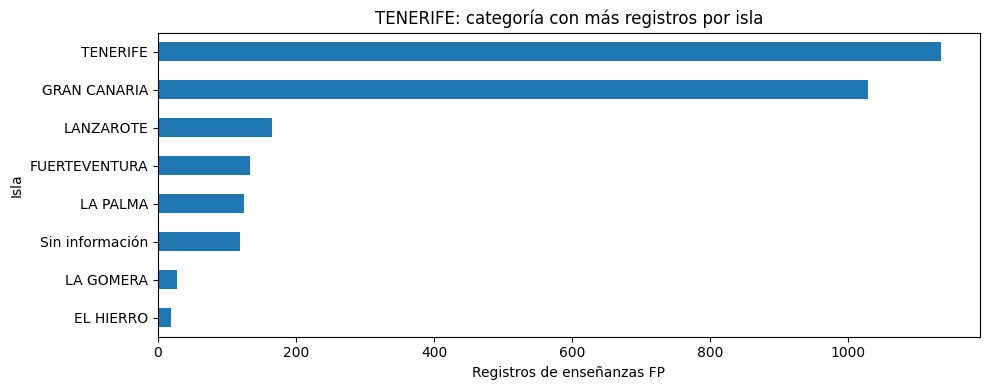

Lectura: TENERIFE concentra 1134 de 2751 registros; no equivale a demanda ni a alumnado.


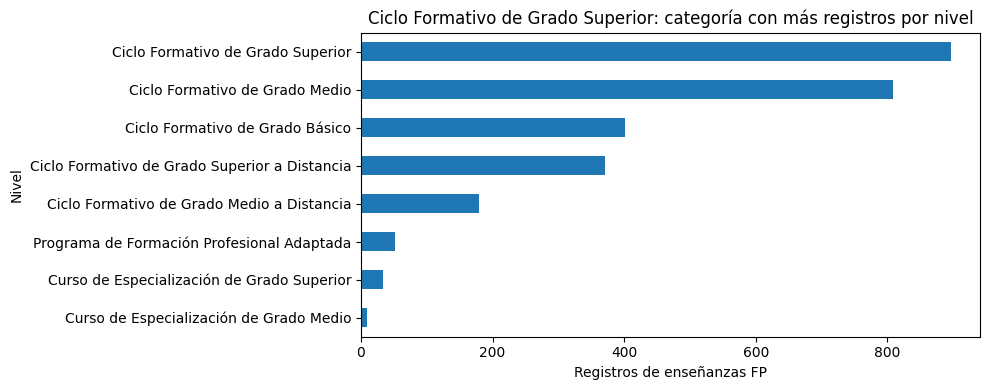

Lectura: Ciclo Formativo de Grado Superior concentra 896 de 2751 registros; no equivale a demanda ni a alumnado.


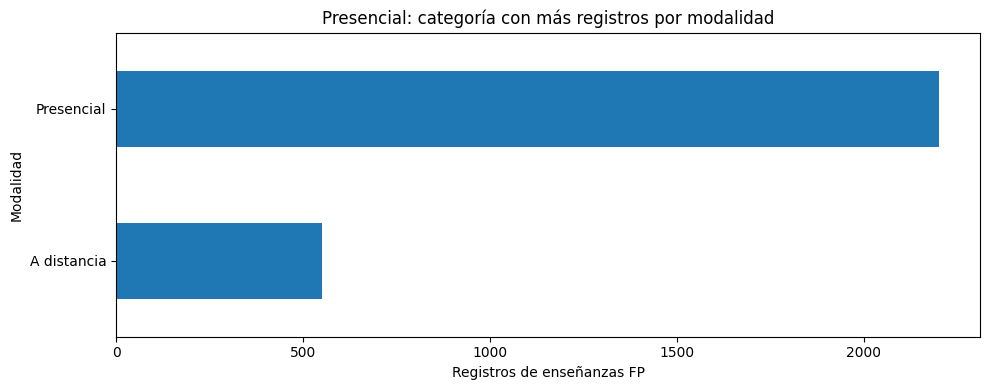

Lectura: Presencial concentra 2201 de 2751 registros; no equivale a demanda ni a alumnado.


In [7]:
for col in ['Isla','Nivel','Modalidad']:
    print(col)
    display(fp[col].value_counts(dropna=False,normalize=True).round(3))
for col in ['Isla','Nivel','Modalidad']:
    counts=fp[col].fillna('Sin información').value_counts()
    ax=counts.sort_values().plot.barh(figsize=(10,4),title=f'{counts.index[0]}: categoría con más registros por {col.lower()}')
    ax.set_xlabel('Registros de enseñanzas FP'); ax.set_ylabel(col)
    plt.tight_layout(); plt.show()
    print(f'Lectura: {counts.index[0]} concentra {counts.iloc[0]} de {len(fp)} registros; no equivale a demanda ni a alumnado.')

## 5. Preparamos el corpus para el asistente

Creamos un documento de texto por cada registro de FP. Incluimos el curso escolar y dejamos fuera los datos de contacto y matrícula. No añadimos requisitos ni salidas profesionales que no aparezcan en los datos.

In [8]:
cols=['CodigoCentro','CodigoEstudio','DenominacionCentro','Isla','Municipio','Nivel','Familia','Estudio','Modalidad','CursoEscolar']
corpus=fp[cols].copy()
corpus['texto']=corpus.apply(lambda row: ' | '.join(f'{col}: {row[col]}' for col in cols if pd.notna(row[col])),axis=1)
corpus['palabras']=corpus.texto.map(lambda t:len(t.split()))
print('Documentos:',len(corpus)); display(corpus.palabras.describe())
display(corpus[['texto','palabras']].head(3))
# Conservamos la reconstrucción en memoria para no modificar los archivos originales.

Documentos: 2751


,palabras
count,2751.00000
mean,51.29771
std,5.01152
min,35.00000
25%,48.00000
50%,51.00000
75%,55.00000
max,66.00000


,texto,palabras
0,CodigoCentro: 35009383 | CodigoEstudio: 4805 |...,53
1,CodigoCentro: 38016829 | CodigoEstudio: 4805 |...,50
2,CodigoCentro: 38017561 | CodigoEstudio: 4805 |...,54


## 6. Resumen de calidad de la oferta

Registramos las incidencias sin corregirlas automáticamente.

In [9]:
semi = fp.Estudio.str.contains(r'Semi\.', case=False, na=False)
calidad = pd.DataFrame([
    ('Nulos', f"{fp.Isla.isna().sum()} registros sin isla; {fp.Municipio.isna().sum()} sin municipio", 'Conservar ausencia; no inventar ubicación'),
    ('Duplicados exactos', str(sum(d.duplicated().sum() for d in datos.values())), 'No eliminar sin justificación'),
    ('Valores raros', f'{len(raros)} ratios fuera de IQR', 'Revisión humana; no eliminar automáticamente'),
    ('Formatos y tipos', f'{semi.sum()} denominaciones con Semi.', 'Conservar modalidad original; evitar preguntas semipresenciales'),
    ('Sesgo y desequilibrio', 'Cobertura desigual por isla y nivel', 'Evaluar diversidad de preguntas'),
    ('Fuga potencial', 'Campos de matrícula y vacantes; respuestas de test', 'Excluir del corpus y del ajuste'),
    ('Vigencia', ', '.join(fp.CursoEscolar.unique()), 'Indicar curso; no garantizar oferta actual')
], columns=['Aspecto','Hallazgo','Acción'])
display(calidad)

,Aspecto,Hallazgo,Acción
0,Nulos,119 registros sin isla; 119 sin municipio,Conservar ausencia; no inventar ubicación
1,Duplicados exactos,0,No eliminar sin justificación
2,Valores raros,288 ratios fuera de IQR,Revisión humana; no eliminar automáticamente
3,Formatos y tipos,192 denominaciones con Semi.,Conservar modalidad original; evitar preguntas...
4,Sesgo y desequilibrio,Cobertura desigual por isla y nivel,Evaluar diversidad de preguntas
5,Fuga potencial,Campos de matrícula y vacantes; respuestas de ...,Excluir del corpus y del ajuste
6,Vigencia,2025/26,Indicar curso; no garantizar oferta actual


## 7. Cargamos y verificamos el corpus definitivo

Utilizamos las fichas de TodoFP contrastadas en Colab y los itinerarios de FP Adaptada documentados mediante BOC y BOE. Conservamos las condiciones de reutilización de cada fuente, tal como figuran en nuestro plan de datos. No atribuimos CC BY 4.0 a TodoFP. La aprobación estructural no sustituye la revisión humana de los textos.

En Colab subimos los cuatro CSV originales y los cuatro archivos de consolidación (tres CSV y un JSON) a la carpeta de trabajo. También podemos conservar estos últimos en `corpus_definitivo/`. No necesitamos conexión a las webs oficiales para ejecutar este EDA.

In [ ]:
import json
nombres = ['corpus_fp_canarias_ampliado.csv', 'informacion_fp_oficial.csv', 'mapa_ensenanzas_fichas.csv', 'control_consolidacion.json']
def localizar(nombre):
    return next((r / nombre for r in [RUTA/'corpus_definitivo', RUTA] if (r/nombre).exists()), None)
if any(localizar(f) is None for f in nombres):
    from google.colab import files
    files.upload()
assert all(localizar(f) is not None for f in nombres), 'Faltan archivos de consolidación'
control = json.loads(localizar(nombres[3]).read_text())
for f in nombres[:3]:
    huella = hashlib.sha256(localizar(f).read_bytes()).hexdigest()
    print(f, huella)
    assert huella == control['sha256'][f], f'El archivo {f} no coincide con la versión consolidada'
ampliado, extra, mapa = [pd.read_csv(localizar(f), keep_default_na=False) for f in nombres[:3]]
assert ampliado.id_documento.is_unique and extra.id_documento.is_unique
assert ampliado.texto.str.strip().ne('').all()
assert len(ampliado) == control['total']
oferta = ampliado[ampliado.tipo_documento.eq('oferta')].copy()
fichas = ampliado[ampliado.tipo_documento.eq('informacion_fp')].copy()
assert len(oferta) == len(corpus) == control['oferta']
assert len(fichas) == len(extra) == control['fichas']
from collections import Counter
assert Counter(oferta.texto) == Counter(corpus.texto), 'Revisar diferencias con la oferta reconstruida'
assert set(fichas.id_documento) == set(extra.id_documento)
print('Documentos por tipo:'); display(ampliado.tipo_documento.value_counts())

## 8. Cobertura y calidad de las fichas

Medimos cobertura por combinación de estudio, nivel y familia, no por número de títulos únicos. No interpretamos los campos geográficos vacíos de las fichas nacionales como errores de ubicación.

In [ ]:
claves = ['Estudio','Nivel','Familia']
assert not mapa.duplicated(claves).any()
assert set(mapa.id_documento) == set(extra.id_documento)
combinaciones = oferta[claves].drop_duplicates()
cobertura = combinaciones.merge(mapa, on=claves, how='left', validate='one_to_one', indicator=True)
assert len(cobertura) == len(mapa) == control['combinaciones_cubiertas']
print('Cobertura:', cobertura._merge.eq('both').sum(), '/', len(cobertura))
assert cobertura._merge.eq('both').all()
for campo in ['requisitos_acceso','salidas_profesionales','continuidad_estudios','fuente','licencia']:
    print(campo, ':', extra[campo].str.strip().ne('').sum(), '/', len(extra))
print('Revisión humana:'); display(extra.revision_humana.replace('', 'No indicado').value_counts())
print('Nulos o vacíos por tipo de documento:')
for tipo, grupo in ampliado.groupby('tipo_documento'):
    print(tipo)
    display(pd.DataFrame({'vacíos':grupo.eq('').sum(), '% vacíos':grupo.eq('').mean().mul(100).round(2)}))
print('Textos repetidos:', ampliado.texto.duplicated().sum())
print('Fuentes principales de fichas:', extra.fuente.nunique())

## 9. Distribución y longitud de los documentos

Comparamos las longitudes porque los textos de acceso y empleo son más extensos que los de oferta. Esta diferencia puede influir en la recuperación TF-IDF. No ajustamos el modelo en este cuaderno.

In [ ]:
ampliado['longitud_calculada'] = ampliado.texto.str.split().str.len()
print('Diferencias con el contador almacenado:', (ampliado.longitud_calculada != ampliado.palabras).sum())
display(ampliado.groupby('tipo_documento').longitud_calculada.describe().round(2))
for tipo, grupo in ampliado.groupby('tipo_documento'):
    ax = grupo.longitud_calculada.plot.hist(bins=20, figsize=(8,3), title=f'Longitud: {tipo}')
    ax.set_xlabel('Palabras'); ax.set_ylabel('Documentos'); plt.tight_layout(); plt.show()
resumen = cobertura.groupby('Nivel').agg(combinaciones=('id_documento','size'), cubiertas=('id_documento','count'))
resumen['cobertura_pct'] = 100*resumen.cubiertas/resumen.combinaciones
display(resumen)
ax = resumen.combinaciones.sort_values().plot.barh(figsize=(10,5), title='Combinaciones cubiertas por nivel')
ax.set_xlabel('Combinaciones de estudio, nivel y familia'); plt.tight_layout(); plt.show()

## 10. Nuestras conclusiones

- Conservamos 2.751 documentos de oferta del curso 2025/26 y añadimos 163 fichas informativas: 2.914 documentos en total. Las 419 combinaciones de enseñanza, nivel y familia tienen una ficha asociada.
- La cobertura estructural no garantiza la exactitud de cada respuesta. Conservamos 154 fichas con revisión humana pendiente y siete fichas de FP Adaptada sin continuidad de estudios específica.
- No inventamos las ubicaciones ausentes ni interpretamos los ratios como plazas disponibles. Conservamos la modalidad original aunque algunas denominaciones incluyan «Semi.».
- Las fichas informativas son más largas que los documentos de oferta; tendremos en cuenta esta diferencia al evaluar la recuperación.
- Cumplir requisitos no garantiza una plaza y las ocupaciones no garantizan empleo. La oferta histórica no acredita la oferta actual.
- Mantenemos las fuentes, atribuciones y condiciones de reutilización. Debemos reconfirmar las condiciones de TodoFP antes de publicar y obtener la aprobación del docente.
- No usamos preguntas ni respuestas del test final para preparar los datos o ajustar el modelo. El siguiente paso es evaluar el baseline con las preguntas de desarrollo separadas y revisar el test antes de congelarlo.
- No sobrescribimos los CSV definitivos: verificamos sus hashes y analizamos copias en memoria.